# Kinyarwanda Sentiment Classification: Fine-tuning AfroXLMR

Pretrained Transformer encoders fine-tuned on the same data and splits as the earlier notebooks. AfroXLMR (Alabi et al., 2022) is XLM-R further adapted to 17 African languages, Kinyarwanda included.

## Setup

In [1]:
!pip install -q transformers

In [2]:
import re, os, json, random, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu")

Device: Tesla T4


## Data
Loading is the same as before. Cleaning drops `@user` and collapses whitespace but skips lowercasing, since the pretrained models were trained on cased text.

In [3]:
base = "hf://datasets/shmuhammad/AfriSenti-twitter-sentiment@refs%2Fconvert%2Fparquet/kin"
ds = load_dataset("parquet", data_files={
    "train":      f"{base}/train/0000.parquet",
    "validation": f"{base}/validation/0000.parquet",
    "test":       f"{base}/test/0000.parquet",
})
label_names = ds["train"].features["label"].names
print("Labels:", label_names)

kin/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  270kB            

kin/train/0000.parquet: downloading bytes:           |  0.00B            

kin/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 66.8kB            

kin/validation/0000.parquet: downloading bytes:           |  0.00B            

kin/test/0000.parquet: reconstructing file:   0%|          |  0.00B / 86.3kB            

kin/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Labels: ['positive', 'neutral', 'negative']


In [4]:
def clean(text):
    return re.sub(r"\s+", " ", re.sub(r"@user", " ", text)).strip()

train_df, val_df, test_df = (ds[s].to_pandas() for s in ("train", "validation", "test"))
for d in (train_df, val_df, test_df):
    d["clean"] = d["tweet"].apply(clean)

y_train, y_val, y_test = (d["label"].tolist() for d in (train_df, val_df, test_df))
print(len(train_df), len(val_df), len(test_df))

3302 827 1026


## Tokenisation
Both model families use a SentencePiece subword vocabulary, so an unseen or misspelled word is split into smaller known pieces instead of becoming `<unk>`. Tweets are truncated at 128 subword tokens.

In [5]:
MAX_LEN = 128
tok = AutoTokenizer.from_pretrained("Davlan/afro-xlmr-base")

lens = np.array([len(tok(t)["input_ids"]) for t in train_df["clean"]])
print(f"Subword tokens per tweet: mean {lens.mean():.1f}, median {np.median(lens):.0f}, max {lens.max()}")
print(f"Tweets longer than {MAX_LEN}: {(lens > MAX_LEN).mean():.1%}")
print(tok.tokenize(train_df["clean"][1])[:20])

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Subword tokens per tweet: mean 39.5, median 39, max 143
Tweets longer than 128: 0.0%
['▁A', 'mahan', 'o', '?!', '▁Ni', '▁i', 'mpan', 'uka', ',', '▁in', 'kan', 'gu', ',', '▁in', 'zara', '.', '...', '▁Muy', 'ite', '▁izin']


## Model
A pretrained encoder with a small classification head on the `<s>` token, producing three class scores. All weights are fine-tuned. Training uses AdamW (weight decay 0.01), a linear warm-up over the first 10% of steps followed by linear decay, batch size 16, mixed precision on GPU, and class-weighted cross-entropy as in the earlier notebooks. Five epochs are run and the epoch with the best validation macro-F1 is kept.

In [12]:
BATCH_SIZE, EVAL_BATCH, EPOCHS = 16, 64, 5
WARMUP, WEIGHT_DECAY = 0.1, 0.01
use_amp = device.type == "cuda"

counts = np.bincount(y_train)
class_weights = torch.tensor(len(y_train) / (len(label_names) * counts), dtype=torch.float32).to(device)

_cache = {}
def get_data(hub_id):
    if hub_id not in _cache:
        t = AutoTokenizer.from_pretrained(hub_id)
        enc = lambda texts: t(list(texts), truncation=True, max_length=MAX_LEN)["input_ids"]
        _cache[hub_id] = (t.pad_token_id, enc(train_df["clean"]), enc(val_df["clean"]), enc(test_df["clean"]))
    return _cache[hub_id]

In [7]:
def make_batches(ids, labels, batch_size, shuffle, pad_id):
    order = np.random.permutation(len(ids)) if shuffle else np.arange(len(ids))
    for s in range(0, len(ids), batch_size):
        idx = order[s:s + batch_size]
        seqs = [ids[i] for i in idx]
        width = max(len(q) for q in seqs)
        x = torch.full((len(seqs), width), pad_id, dtype=torch.long)
        mask = torch.zeros((len(seqs), width), dtype=torch.long)
        for j, q in enumerate(seqs):
            x[j, :len(q)] = torch.tensor(q)
            mask[j, :len(q)] = 1
        y = torch.tensor([labels[i] for i in idx])
        yield x.to(device), mask.to(device), y.to(device)

def predict(model, ids, labels, pad_id):
    model.eval()
    preds = []
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
        for x, mask, _ in make_batches(ids, labels, EVAL_BATCH, False, pad_id):
            preds += model(input_ids=x, attention_mask=mask).logits.argmax(-1).tolist()
    return preds

def scores(y_true, y_pred):
    _, _, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1}

In [8]:
def run(hub_id, lr, seed, save_dir=None):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    pad_id, tr, va, te = get_data(hub_id)
    model = AutoModelForSequenceClassification.from_pretrained(
        hub_id, num_labels=len(label_names),
        id2label=dict(enumerate(label_names)),
        label2id={n: i for i, n in enumerate(label_names)}).float().to(device)  # some checkpoints load as fp16

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * ((len(tr) + BATCH_SIZE - 1) // BATCH_SIZE)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)

    best, history = {"val_macro_f1": -1}, []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for x, mask, y in make_batches(tr, y_train, BATCH_SIZE, True, pad_id):
            optimizer.zero_grad()
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=x, attention_mask=mask).logits
            scaler.scale(loss_fn(logits.float(), y)).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            scheduler.step()

        val_f1 = scores(y_val, predict(model, va, y_val, pad_id))["macro_f1"]
        history.append(val_f1)
        if val_f1 > best["val_macro_f1"]:
            test_preds = predict(model, te, y_test, pad_id)
            test = scores(y_test, test_preds)
            best = {"val_macro_f1": val_f1, "best_epoch": epoch, "test_macro_f1": test["macro_f1"],
                    "test_accuracy": test["accuracy"], "test_preds": test_preds}
            if save_dir:
                model.save_pretrained(save_dir)

    best["history"] = history
    del model, optimizer
    gc.collect(); torch.cuda.empty_cache()
    return best

## Experiments
Four configurations, each run with three seeds. The test score is taken at the epoch with the best validation score.
- AfroXLMR-base at a learning rate of 2e-5, the reference setting
- AfroXLMR-base at 5e-5, to see how sensitive training is to the learning rate
- XLM-R base at 2e-5, the same architecture without the African-language adaptation, to test whether that adaptation matters
- AfroXLMR-large at 1e-5, to test whether a larger model helps

In [9]:
CONFIGS = [
    ("AfroXLMR-base, lr 2e-5",  "Davlan/afro-xlmr-base",       2e-5),
    ("AfroXLMR-base, lr 5e-5",  "Davlan/afro-xlmr-base",       5e-5),
    ("XLM-R base, lr 2e-5",     "FacebookAI/xlm-roberta-base", 2e-5),
    ("AfroXLMR-large, lr 1e-5", "Davlan/afro-xlmr-large",      1e-5),
]
SEEDS = [42, 43, 44]

# Results are saved after each configuration so a disconnect does not lose finished runs
runs = json.load(open("finetune_runs.json")) if os.path.exists("finetune_runs.json") else {}
for name, hub_id, lr in CONFIGS:
    if name in runs:
        continue
    t0 = time.time()
    runs[name] = [run(hub_id, lr, s) for s in SEEDS]
    json.dump(runs, open("finetune_runs.json", "w"))
    r = runs[name]
    print(f"{name}: val F1 {np.mean([x['val_macro_f1'] for x in r]):.3f} | "
          f"test F1 {np.mean([x['test_macro_f1'] for x in r]):.3f} | "
          f"epochs {[x['best_epoch'] for x in r]} | {(time.time() - t0) / 60:.1f} min")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-large
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_1233/573844491.py:26: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order:

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-large
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_1233/573844491.py:26: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order:

AfroXLMR-large, lr 1e-5: val F1 0.704 | test F1 0.707 | epochs [3, 3, 4] | 22.9 min


## Results

In [10]:
def load_json(fname, origin):
    if not os.path.exists(fname):
        from google.colab import files
        print(f"Select {fname} ({origin})"); files.upload()
    return json.load(open(fname))

def mean_std(r, key):
    v = [x[key] for x in r]
    return f"{np.mean(v):.3f} ± {np.std(v):.3f}"   # population std (ddof=0) over three seeds

rows = [{"model": name,
         "val macro-F1": mean_std(r, "val_macro_f1"),
         "test macro-F1": mean_std(r, "test_macro_f1"),
         "test accuracy": mean_std(r, "test_accuracy")}
        for name, r in runs.items()]

# Earlier notebooks: read from their saved files rather than typing the numbers in
base_res = load_json("baseline_results.json", "notebook 01")
seq_runs = load_json("sequence_runs.json", "notebook 02")
for label, key in [("TF-IDF word + LR (baseline)", "tfidf_word_LR"), ("TF-IDF char + LR (baseline)", "tfidf_char_LR")]:
    rows.append({"model": label,
                 "val macro-F1": f"{base_res[key + ' (val)']['macro_f1']:.3f}",
                 "test macro-F1": f"{base_res[key + ' (test)']['macro_f1']:.3f}",
                 "test accuracy": f"{base_res[key + ' (test)']['accuracy']:.3f}"})
r = seq_runs["BiLSTM + Word2Vec (fine-tuned)"]
rows.append({"model": "BiLSTM + Word2Vec (fine-tuned)", "val macro-F1": mean_std(r, "val_macro_f1"),
             "test macro-F1": mean_std(r, "test_macro_f1"), "test accuracy": mean_std(r, "test_accuracy")})
table = pd.DataFrame(rows).set_index("model")
table.to_csv("finetune_results.csv")
table

Select baseline_results.json (notebook 01)


Saving baseline_results.json to baseline_results.json
Select sequence_runs.json (notebook 02)


Saving sequence_runs.json to sequence_runs.json


,val macro-F1,test macro-F1,test accuracy
model,,,
"AfroXLMR-base, lr 2e-5",0.669 ± 0.004,0.663 ± 0.008,0.661 ± 0.007
"AfroXLMR-base, lr 5e-5",0.661 ± 0.007,0.668 ± 0.006,0.665 ± 0.006
"XLM-R base, lr 2e-5",0.558 ± 0.015,0.540 ± 0.019,0.554 ± 0.013
"AfroXLMR-large, lr 1e-5",0.704 ± 0.008,0.707 ± 0.008,0.704 ± 0.009
TF-IDF word + LR (baseline),0.579,0.567,0.562
TF-IDF char + LR (baseline),0.642,0.597,0.595
BiLSTM + Word2Vec (fine-tuned),0.612 ± 0.006,0.580 ± 0.002,0.578 ± 0.001


± is the population standard deviation over three seeds (`np.std`). With three seeds it is only a rough guide to run-to-run variation. The TF-IDF baselines are single deterministic runs. Differences smaller than roughly 0.03 macro-F1 are within the sampling noise of a 1,026-tweet test set (see notebook 05 for bootstrap confidence intervals), so they should not be reported as wins.

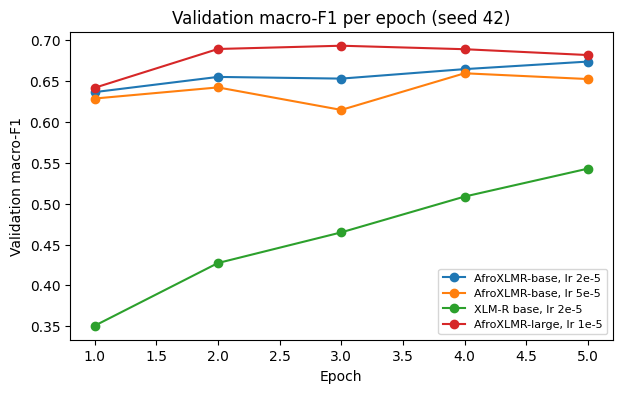

In [11]:
plt.figure(figsize=(7, 4))
for name, r in runs.items():
    plt.plot(range(1, len(r[0]["history"]) + 1), r[0]["history"], marker="o", label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation macro-F1")
plt.title("Validation macro-F1 per epoch (seed 42)")
plt.legend(fontsize=8); plt.show()

### Observations
*Draft written from the printed numbers. Rewrite it in your own words and check it against the output before using it.*

- **Size and adaptation matter most.** AfroXLMR-large reaches 0.707 ± 0.008 test macro-F1, against 0.663 ± 0.008 for AfroXLMR-base. A paired bootstrap on the same test tweets gives +0.034, +0.043 and +0.056 for seeds 42, 43 and 44, and every interval excludes 0 (notebook 05).
- **Learning rate 2e-5 vs 5e-5 makes no measurable difference** (0.663 vs 0.668; paired differences -0.002, -0.006 and +0.022, all intervals include 0). Validation prefers 2e-5, but the gap is smaller than the noise.
- **XLM-R base is far behind (0.540) and below every non-Transformer model, but it was still improving.** Its best epoch was the last one (5) in all three seeds and validation macro-F1 rose from about 0.35 to about 0.55 over the five epochs, so part of the 0.12 gap to AfroXLMR-base is slower convergence at this learning rate and epoch budget, not only the missing African-language adaptation. Notebook 03c has an optional 10-epoch check.
- **The deployed model is the lowest of the three large seeds** (0.697, against 0.715 and 0.710 for seeds 43 and 44). Report 0.707 ± 0.008 as the experiment result and 0.697 as the score of the uploaded model, and say why they differ.
- The warning "`lr_scheduler.step()` before `optimizer.step()`" is harmless here: with mixed precision the GradScaler skips the very first optimizer step while it calibrates its scale.

## Final model
The selected configuration is retrained and uploaded in `03b_final_model_and_upload.ipynb`, which also writes the per-class report, confusion matrix and test predictions of the deployed model.